# Pneumonia Detection from Chest X-Rays: Classical ML vs. Fine-Tuned ResNet50

Binary classification (normal vs. pneumonia) on pediatric chest X-rays. Two approaches are compared on exactly the same data:

1. **Classical ML:** SVM and Random Forest on hand-crafted texture (GLCM) and intensity-histogram features after CLAHE contrast enhancement.
2. **Deep learning:** ResNet50 pretrained on ImageNet, fine-tuned in two stages, with Grad-CAM heatmaps for inspection.

- **Data:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) from Kaggle.
- **Framework:** TensorFlow / Keras, scikit-learn.

**Evaluation design (important):**
- The training images are split into train and validation **by patient**. One patient contributes several images, and a random image-level split would leak patients between the two sets.
- All three models use the **same training images, the same validation images and the same test set**.
- Hyperparameters and the decision threshold are chosen on the validation set only. The test set is used once for the final numbers.
- Test metrics come with 95% confidence intervals from a patient-level bootstrap.

In [1]:
!pip install -q kagglehub scikit-image

In [2]:
import os
import re
import time
import random
import warnings
from glob import glob
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display
from joblib import Parallel, delayed
from skimage.feature import graycomatrix, graycoprops
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

# ---- Configuration ----
SEED = 42
CLASSES = ["NORMAL", "PNEUMONIA"]   # label 0 = normal, label 1 = pneumonia
IMG_SIZE = (224, 224)                # input size of the ResNet50
CLASSIC_SIZE = 128                   # image size for the classical feature pipeline
BATCH_SIZE = 32
EPOCHS_HEAD = 10                     # stage 1: train the new classification head only
EPOCHS_FT = 20                       # stage 2: fine-tune the top of the ResNet50
N_UNFREEZE = 30                      # layers unfrozen in stage 2 (batch-norm layers stay frozen)
N_BOOT = 1000                        # bootstrap resamples for confidence intervals
WEIGHTS = "imagenet"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data and patient-level split

The official `val` folder of this dataset has only 16 images, which is too small to select models reliably, so it is ignored. Instead, the official `train` folder is split 80/20 into training and validation images **by patient**. The official `test` folder is kept untouched for the final evaluation.

Patient IDs are parsed from the file names (`person12_bacteria_34.jpeg`, `IM-0115-0001.jpeg`). The notebook checks that no patient appears in more than one split.

In [3]:
print("Downloading dataset from Kaggle...")
base_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

def find_data_root(base):
    """Locate the folder that contains train/ and test/ (the archive also holds a nested duplicate and __MACOSX)."""
    cands = [os.path.dirname(p) for p in glob(os.path.join(base, "**", "train"), recursive=True) if os.path.isdir(p)]
    cands = [c for c in cands if os.path.isdir(os.path.join(c, "test")) and "__MACOSX" not in c]
    return min(cands, key=len)

DATA_DIR = Path(find_data_root(base_path))
print("Data root:", DATA_DIR)

def list_images(split_dir):
    paths, labels = [], []
    for label, cls in enumerate(CLASSES):
        files = sorted(glob(str(split_dir / cls / "*.jp*g")))
        paths += files
        labels += [label] * len(files)
    return np.array(paths), np.array(labels)

def patient_id(path):
    """Parse the patient ID from the file name; unknown patterns fall back to one ID per image."""
    name = os.path.basename(path)
    m = re.match(r"(person\d+_(?:bacteria|virus))_", name) or re.match(r"(person\d+)_", name)
    if m:
        return m.group(1)
    m = re.match(r"((?:NORMAL2-)?IM-\d+)-", name)
    if m:
        return m.group(1)
    return os.path.splitext(name)[0]

all_train_paths, all_train_labels = list_images(DATA_DIR / "train")
test_paths, y_test = list_images(DATA_DIR / "test")
all_train_groups = np.array([patient_id(p) for p in all_train_paths])
test_groups = np.array([patient_id(p) for p in test_paths])

# Patient-level 80/20 split of the official training folder
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(splitter.split(all_train_paths, all_train_labels, groups=all_train_groups))
train_paths, y_train, train_groups = all_train_paths[tr_idx], all_train_labels[tr_idx], all_train_groups[tr_idx]
val_paths,   y_val,   val_groups   = all_train_paths[va_idx], all_train_labels[va_idx], all_train_groups[va_idx]

# Sanity checks
assert not set(train_groups) & set(val_groups), "Patient leakage between train and validation!"
print(f"Training images with a parsed patient ID: {np.mean([g != os.path.splitext(os.path.basename(p))[0] for p, g in zip(all_train_paths, all_train_groups)]):.0%}")
print(f"Patients shared between train and test: {len(set(train_groups) & set(test_groups)) + len(set(val_groups) & set(test_groups))}")

summary = pd.DataFrame({
    "Images": [len(y_train), len(y_val), len(y_test)],
    "Patients": [len(set(train_groups)), len(set(val_groups)), len(set(test_groups))],
    "Normal": [int((y_train == 0).sum()), int((y_val == 0).sum()), int((y_test == 0).sum())],
    "Pneumonia": [int((y_train == 1).sum()), int((y_val == 1).sum()), int((y_test == 1).sum())],
}, index=["Train", "Validation", "Test"])
summary["% pneumonia"] = (100 * summary["Pneumonia"] / summary["Images"]).round(1)
display(summary)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Data root: /kaggle/input/chest-xray-pneumonia/chest_xray
Training images with a parsed patient ID: 100%
Patients shared between train and test: 0


,Images,Patients,Normal,Pneumonia,% pneumonia
Train,4157,2923,1041,3116,75.0
Validation,1059,731,300,759,71.7
Test,624,428,234,390,62.5


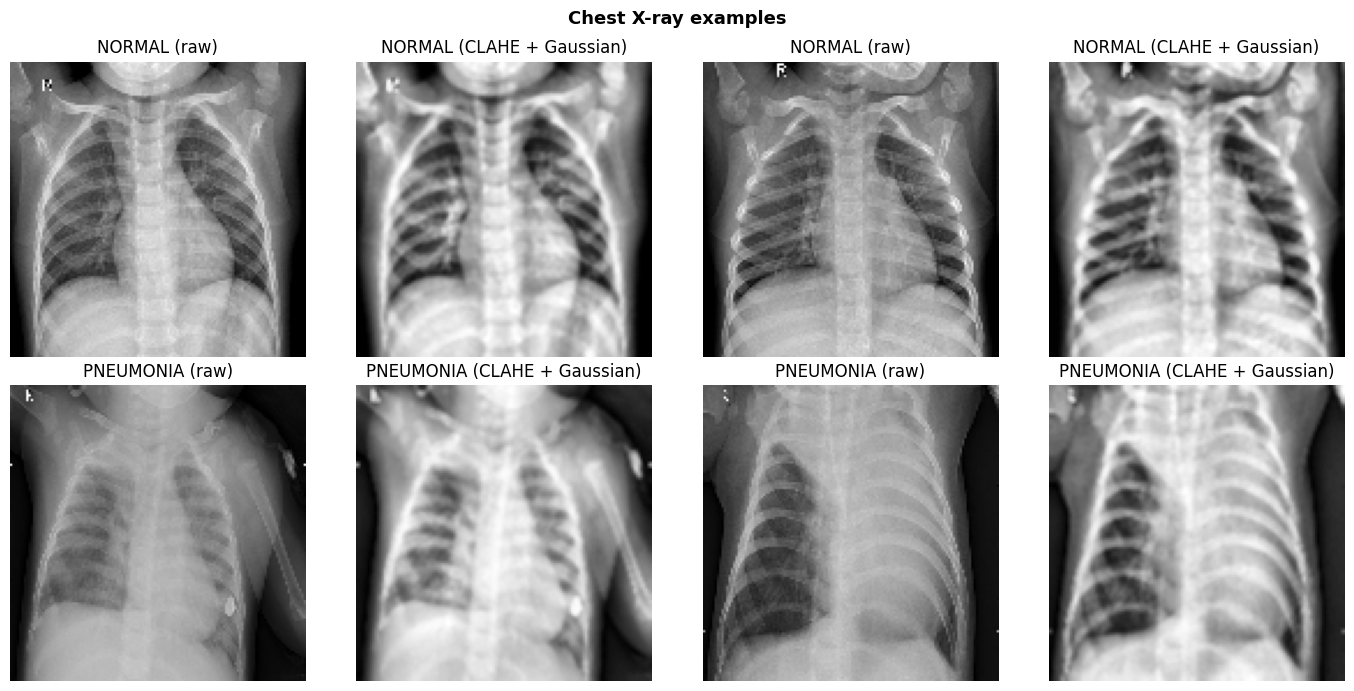

In [4]:
def read_gray(path, size):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return None if img is None else cv2.resize(img, (size, size))

def preprocess_classic(path):
    """Resize, light Gaussian denoising and CLAHE contrast enhancement."""
    img = read_gray(path, CLASSIC_SIZE)
    img = cv2.GaussianBlur(img, (3, 3), 0)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)

# Example images: raw vs. preprocessed, two per class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, label in enumerate([0, 1]):
    picks = rng.choice(np.where(y_train == label)[0], size=2, replace=False)
    for k, i in enumerate(picks):
        axes[row, 2 * k].imshow(read_gray(train_paths[i], CLASSIC_SIZE), cmap="gray")
        axes[row, 2 * k].set_title(f"{CLASSES[label]} (raw)")
        axes[row, 2 * k + 1].imshow(preprocess_classic(train_paths[i]), cmap="gray")
        axes[row, 2 * k + 1].set_title(f"{CLASSES[label]} (CLAHE + Gaussian)")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Chest X-ray examples", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 2. Shared evaluation tools

- **Operating point:** a classifier outputs a probability, and the decision threshold decides how many cases are flagged. The default of 0.5 is arbitrary here because pneumonia is the majority class (about 74% of training images). For each model the threshold is therefore also chosen on the **validation** set by maximizing Youden's J (sensitivity + specificity - 1). Results are shown at both thresholds.
- **Confidence intervals:** 95% intervals from a bootstrap that resamples whole patients, so repeated images of one patient are not treated as independent.

In [5]:
METRICS = ["AUC", "Accuracy", "BalAcc", "Sensitivity", "Specificity", "Precision", "F1"]

def metrics_at(y, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    sens, spec, prec = div(tp, tp + fn), div(tn, tn + fp), div(tp, tp + fp)
    return {"AUC": roc_auc_score(y, prob), "Accuracy": (tp + tn) / len(y),
            "BalAcc": (sens + spec) / 2, "Sensitivity": sens, "Specificity": spec,
            "Precision": prec, "F1": div(2 * prec * sens, prec + sens) if prec == prec and sens == sens else np.nan}

def youden_threshold(y, prob):
    fpr, tpr, thr = roc_curve(y, prob)
    t = float(thr[np.argmax(tpr - fpr)])
    return t if np.isfinite(t) else 0.5

def bootstrap_ci(y, prob, thr, groups, n_boot=N_BOOT, seed=SEED):
    """95% CI from resampling whole patients (groups) with replacement."""
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    members = [np.where(groups == g)[0] for g in uniq]
    samples = {k: [] for k in METRICS}
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        idx = np.concatenate([members[i] for i in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        for k, v in metrics_at(y[idx], prob[idx], thr).items():
            samples[k].append(v)
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in samples.items()}

scores = {}   # model name -> {"val": probabilities, "test": probabilities}
timing = {}   # model name -> training / inference seconds

## 3. Classical ML: texture and histogram features

Each image is resized to 128x128, denoised, contrast-enhanced with CLAHE, and described by 52 numbers:

- **GLCM texture (20):** contrast, dissimilarity, homogeneity, energy and correlation of the gray-level co-occurrence matrix at four angles.
- **Intensity histogram (32 bins).**

Features are standardized with statistics from the training images only. The SVM's `C` and the Random Forest's `min_samples_leaf` are chosen by validation AUC. Unlike a quick prototype, these models train on **all** training images and are tested on the **full** test set, the same data the neural network uses.

In [6]:
def classic_features(path):
    img = preprocess_classic(path)
    glcm = graycomatrix(img, distances=[1], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=256, symmetric=True, normed=True)
    texture = np.concatenate([graycoprops(glcm, p).ravel()
                              for p in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]])
    hist, _ = np.histogram(img, bins=32, range=(0, 256))
    return np.concatenate([texture, hist / hist.sum()])

def extract(paths):
    return np.array(Parallel(n_jobs=-1)(delayed(classic_features)(p) for p in paths))

t0 = time.time()
X_train, X_val, X_test = extract(train_paths), extract(val_paths), extract(test_paths)
print(f"Feature matrices: train {X_train.shape}, val {X_val.shape}, test {X_test.shape} ({time.time() - t0:.0f}s)")

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

def select_and_fit(name, make_model, grid):
    best = None
    for value in grid:
        t0 = time.time()
        clf = make_model(value).fit(X_train_s, y_train)
        fit_time = time.time() - t0
        val_auc = roc_auc_score(y_val, clf.predict_proba(X_val_s)[:, 1])
        print(f"  {name}: {value} -> validation AUC {val_auc:.4f}")
        if best is None or val_auc > best[0]:
            best = (val_auc, value, clf, fit_time)
    _, value, clf, fit_time = best
    t0 = time.time()
    scores[name] = {"val": clf.predict_proba(X_val_s)[:, 1], "test": clf.predict_proba(X_test_s)[:, 1]}
    timing[name] = {"train_s": fit_time, "infer_s": time.time() - t0}
    print(f"  -> selected {value}\n")

print("SVM (RBF kernel), choosing C:")
select_and_fit("SVM (RBF)", lambda C: SVC(kernel="rbf", C=C, gamma="scale", probability=True,
                                           class_weight="balanced", random_state=SEED), [1, 10, 100])
print("Random Forest, choosing min_samples_leaf:")
select_and_fit("Random Forest", lambda m: RandomForestClassifier(n_estimators=300, min_samples_leaf=m,
                                                                  class_weight="balanced", random_state=SEED, n_jobs=-1), [1, 3, 5])

Feature matrices: train (4157, 52), val (1059, 52), test (624, 52) (211s)
SVM (RBF kernel), choosing C:
  SVM (RBF): 1 -> validation AUC 0.9698
  SVM (RBF): 10 -> validation AUC 0.9719
  SVM (RBF): 100 -> validation AUC 0.9661
  -> selected 10

Random Forest, choosing min_samples_leaf:
  Random Forest: 1 -> validation AUC 0.9711
  Random Forest: 3 -> validation AUC 0.9701
  Random Forest: 5 -> validation AUC 0.9691
  -> selected 1



## 4. Deep learning: two-stage fine-tuning of ResNet50

- **Input pipeline:** `tf.data`, images resized to 224x224 and preprocessed exactly as ResNet50 expects (`resnet50.preprocess_input`).
- **Augmentation (training only, inside the model):** small rotations, zooms and shifts. Horizontal flips are deliberately not used, because left-right flipping changes the anatomy of a chest X-ray (heart position).
- **Class imbalance:** inverse-frequency class weights.
- **Stage 1:** the ImageNet backbone is frozen and only the new classification head is trained (learning rate 1e-3).
- **Stage 2:** the last 30 backbone layers are unfrozen (batch-norm layers stay frozen) and trained with a small learning rate (2e-5).
- **Model selection:** each stage restores the weights with the best **validation AUC** (patient-level validation set), with fresh callbacks per stage.

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(paths, labels, training):
    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        img = keras.applications.resnet50.preprocess_input(img)
        return img, tf.cast(label, tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((list(paths), labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds   = make_dataset(val_paths,   y_val,   training=False)
test_ds  = make_dataset(test_paths,  y_test,  training=False)

n = len(y_train)
class_weight = {0: n / (2 * (y_train == 0).sum()), 1: n / (2 * (y_train == 1).sum())}
print("Class weights:", {k: round(float(v), 3) for k, v in class_weight.items()})

def build_model(weights):
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = layers.RandomRotation(0.03, fill_mode="constant")(inputs)      # about +/- 11 degrees
    x = layers.RandomZoom(0.1, fill_mode="constant")(x)
    x = layers.RandomTranslation(0.05, 0.05, fill_mode="constant")(x)
    # The backbone is built on top of the augmentation layers so that every ResNet layer
    # belongs to this single model graph (this is what makes Grad-CAM straightforward later).
    base = keras.applications.ResNet50(weights=weights, include_top=False, input_tensor=x)
    h = layers.GlobalAveragePooling2D()(base.output)
    h = layers.Dense(256, activation="relu")(h)
    h = layers.Dropout(0.5)(h)
    outputs = layers.Dense(1, activation="sigmoid")(h)
    return keras.Model(inputs, outputs, name="ResNet50_pneumonia"), base

model, base_model = build_model(WEIGHTS)
base_model.trainable = False   # stage 1: backbone frozen

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")])

def run_stage(title, epochs, lr, patience):
    compile_model(lr)
    n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"=== {title} | trainable parameters: {n_trainable:,} ===")
    cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience,
                                         restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                             min_lr=1e-7, verbose=1)]
    t0 = time.time()
    hist = model.fit(train_ds, epochs=epochs, validation_data=val_ds, class_weight=class_weight,
                     callbacks=cbs, verbose=1)
    return hist, time.time() - t0

history1, time1 = run_stage("Stage 1: classification head", EPOCHS_HEAD, 1e-3, patience=3)

Class weights: {0: 1.997, 1: 0.667}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
=== Stage 1: classification head | trainable parameters: 524,801 ===
Epoch 1/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 53s 307ms/step - accuracy: 0.8828 - auc: 0.9477 - loss: 0.3112 - val_accuracy: 0.9358 - val_auc: 0.9898 - val_loss: 0.1715 - learning_rate: 0.0010
Epoch 2/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 309ms/step - accuracy: 0.9391 - auc: 0.9843 - loss: 0.1560 - val_accuracy: 0.8820 - val_auc: 0.9884 - val_loss: 0.3365 - learning_rate: 0.0010
Epoch 3/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 51s 389ms/step - accuracy: 0.9439 - auc: 0.9872 - loss: 0.1410 - val_accuracy: 0.9575 - val_auc: 0.9938 - val_loss: 0.1128 - learning_rate: 0.0010
Epoch 4/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 38s 291ms/step - accuracy: 0.9473 - auc: 0.9877 - loss: 0.1370 - val_accuracy: 0.9405 - val_auc: 0.9936 - val_loss: 0.1526 - learning_rate: 0.0010
Epoch 5/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 44s 316ms/step - accuracy: 0.9538 - auc: 0.9904 - loss: 

In [8]:
# Stage 2: unfreeze the top of the backbone (batch-norm layers stay frozen)
base_model.trainable = True
for layer in base_model.layers[:-N_UNFREEZE]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

history2, time2 = run_stage("Stage 2: fine-tuning", EPOCHS_FT, 2e-5, patience=4)
print(f"\nTotal training time: {(time1 + time2) / 60:.1f} min")

# Predictions with the best validation weights
t0 = time.time()
val_prob = model.predict(val_ds, verbose=0).ravel()
test_prob = model.predict(test_ds, verbose=0).ravel()
scores["ResNet50 (fine-tuned)"] = {"val": val_prob, "test": test_prob}
timing["ResNet50 (fine-tuned)"] = {"train_s": time1 + time2, "infer_s": time.time() - t0}

=== Stage 2: fine-tuning | trainable parameters: 14,953,473 ===
Epoch 1/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 53s 333ms/step - accuracy: 0.9654 - auc: 0.9943 - loss: 0.0918 - val_accuracy: 0.9245 - val_auc: 0.9902 - val_loss: 0.2281 - learning_rate: 2.0000e-05
Epoch 2/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 39s 299ms/step - accuracy: 0.9663 - auc: 0.9950 - loss: 0.0819 - val_accuracy: 0.9150 - val_auc: 0.9934 - val_loss: 0.2337 - learning_rate: 2.0000e-05
Epoch 3/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.9797 - auc: 0.9980 - loss: 0.0557
Epoch 3: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
130/130 ━━━━━━━━━━━━━━━━━━━━ 41s 299ms/step - accuracy: 0.9764 - auc: 0.9977 - loss: 0.0587 - val_accuracy: 0.8404 - val_auc: 0.9747 - val_loss: 0.6029 - learning_rate: 2.0000e-05
Epoch 4/20
130/130 ━━━━━━━━━━━━━━━━━━━━ 39s 303ms/step - accuracy: 0.9836 - auc: 0.9986 - loss: 0.0426 - val_accuracy: 0.9377 - val_auc: 0.9934 - val_loss: 0.2049 - learning_rate: 1.0000e-05
Epoch

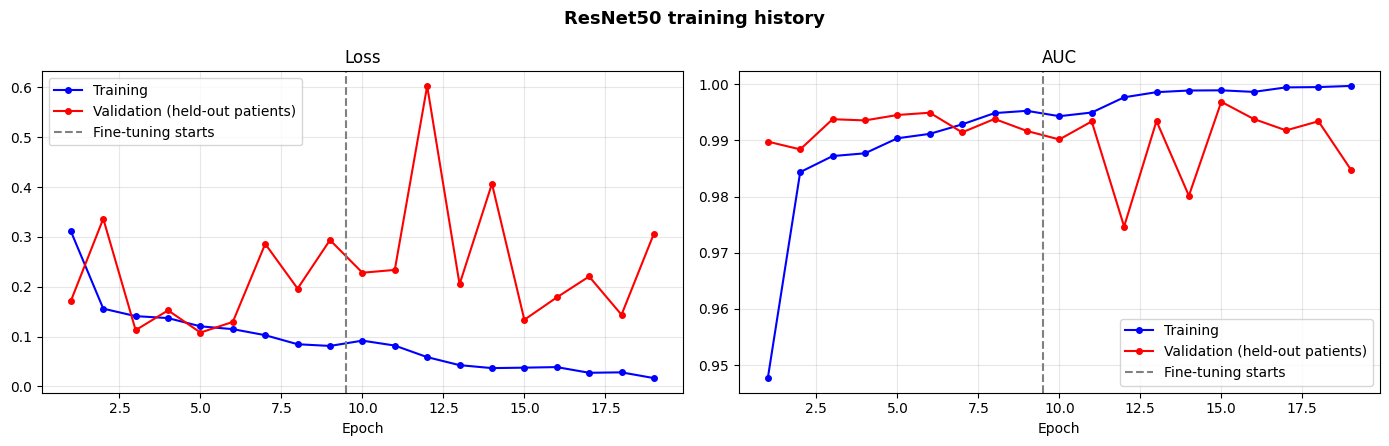

In [9]:
h1, h2 = history1.history, history2.history
merged = {k: h1[k] + h2[k] for k in h1}
ep = range(1, len(merged["loss"]) + 1)
boundary = len(h1["loss"]) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, key, title in [(axes[0], "loss", "Loss"), (axes[1], "auc", "AUC")]:
    ax.plot(ep, merged[key], "b-o", markersize=4, label="Training")
    ax.plot(ep, merged["val_" + key], "r-o", markersize=4, label="Validation (held-out patients)")
    ax.axvline(boundary, color="gray", linestyle="--", label="Fine-tuning starts")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(True, alpha=0.3); ax.legend()
plt.suptitle("ResNet50 training history", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Results on the test set

Both operating points are reported for every model: the default threshold of 0.5, and the threshold chosen on the validation set. Values are shown as estimate [95% CI].

In [10]:
thresholds = {name: youden_threshold(y_val, s["val"]) for name, s in scores.items()}
print("Thresholds chosen on validation patients:", {k: round(v, 3) for k, v in thresholds.items()})

def results_table(use_tuned):
    rows = []
    for name, s in scores.items():
        thr = thresholds[name] if use_tuned else 0.5
        m = metrics_at(y_test, s["test"], thr)
        ci = bootstrap_ci(y_test, s["test"], thr, test_groups)
        row = {"Model": name, "Threshold": round(thr, 3)}
        row.update({k: f"{m[k]:.3f} [{ci[k][0]:.3f}, {ci[k][1]:.3f}]" for k in METRICS})
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

pd.set_option("display.width", 250, "display.max_columns", 20, "display.max_colwidth", 40)
print("\n=== Test results, default threshold 0.5 ===")
display(results_table(False))
print("=== Test results, threshold chosen on validation set ===")
display(results_table(True))

print("Training / inference time (seconds):")
display(pd.DataFrame(timing).T.round(1))

Thresholds chosen on validation patients: {'SVM (RBF)': 0.677, 'Random Forest': 0.62, 'ResNet50 (fine-tuned)': 0.048}

=== Test results, default threshold 0.5 ===


,Threshold,AUC,Accuracy,BalAcc,Sensitivity,Specificity,Precision,F1
Model,,,,,,,,
SVM (RBF),0.5,"0.812 [0.776, 0.848]","0.710 [0.668, 0.752]","0.629 [0.600, 0.660]","0.954 [0.935, 0.974]","0.303 [0.248, 0.359]","0.695 [0.643, 0.746]","0.804 [0.768, 0.838]"
Random Forest,0.5,"0.853 [0.825, 0.881]","0.694 [0.652, 0.737]","0.606 [0.575, 0.636]","0.959 [0.939, 0.977]","0.252 [0.197, 0.308]","0.681 [0.631, 0.729]","0.797 [0.759, 0.830]"
ResNet50 (fine-tuned),0.5,"0.971 [0.957, 0.983]","0.913 [0.889, 0.936]","0.892 [0.865, 0.918]","0.977 [0.960, 0.991]","0.808 [0.755, 0.860]","0.894 [0.860, 0.926]","0.934 [0.913, 0.952]"


=== Test results, threshold chosen on validation set ===


,Threshold,AUC,Accuracy,BalAcc,Sensitivity,Specificity,Precision,F1
Model,,,,,,,,
SVM (RBF),0.677,"0.812 [0.776, 0.848]","0.744 [0.706, 0.780]","0.685 [0.650, 0.724]","0.921 [0.897, 0.943]","0.449 [0.385, 0.519]","0.736 [0.685, 0.783]","0.818 [0.784, 0.848]"
Random Forest,0.620,"0.853 [0.825, 0.881]","0.732 [0.694, 0.771]","0.668 [0.634, 0.703]","0.926 [0.902, 0.951]","0.410 [0.345, 0.475]","0.723 [0.673, 0.770]","0.812 [0.778, 0.844]"
ResNet50 (fine-tuned),0.048,"0.971 [0.957, 0.983]","0.877 [0.847, 0.906]","0.836 [0.806, 0.869]","0.997 [0.992, 1.000]","0.675 [0.616, 0.740]","0.837 [0.796, 0.875]","0.910 [0.885, 0.933]"


Training / inference time (seconds):


,train_s,infer_s
SVM (RBF),1.9,0.1
Random Forest,6.3,0.2
ResNet50 (fine-tuned),803.3,17.0


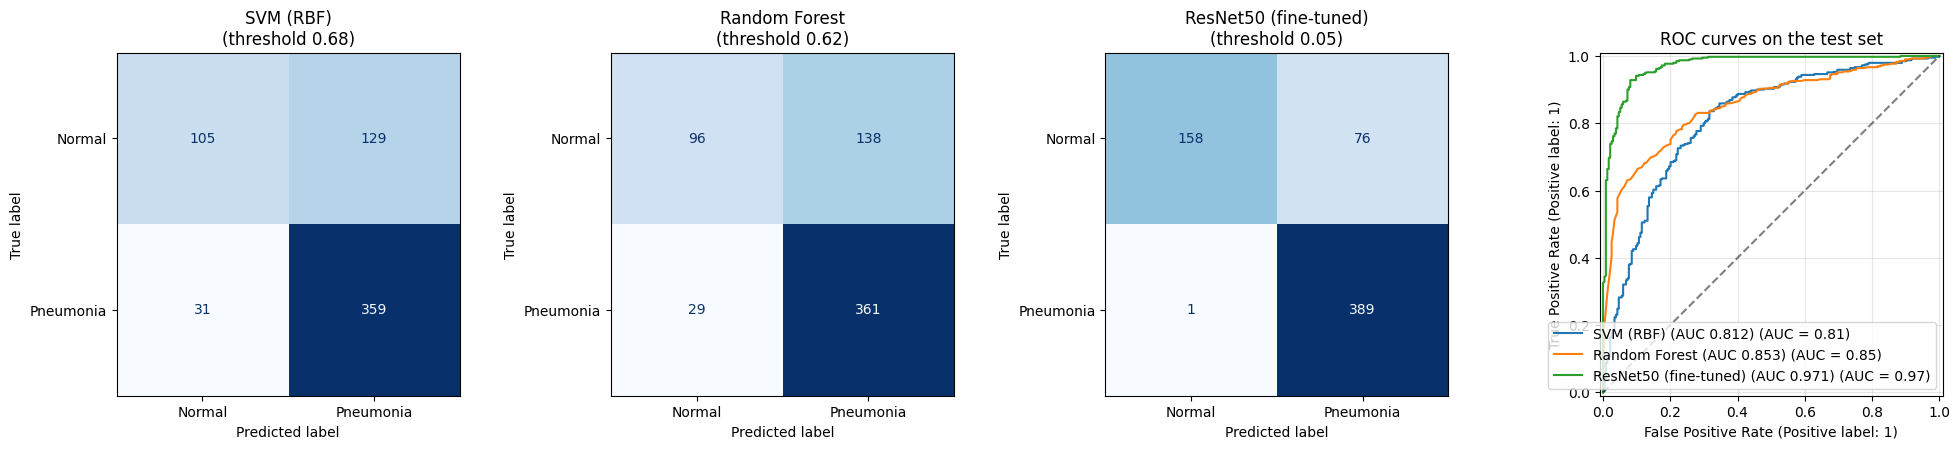

In [11]:
fig, axes = plt.subplots(1, len(scores) + 1, figsize=(5 * (len(scores) + 1), 4.5))
for ax, (name, s) in zip(axes, scores.items()):
    pred = (s["test"] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Normal", "Pneumonia"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(threshold {thresholds[name]:.2f})")

ax = axes[-1]
for name, s in scores.items():
    auc = roc_auc_score(y_test, s["test"])
    RocCurveDisplay.from_predictions(y_test, s["test"], name=f"{name} (AUC {auc:.3f})", ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_title("ROC curves on the test set"); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. What does the network look at? (Grad-CAM)

Grad-CAM highlights the image regions that most increase the model's pneumonia probability. The examples are chosen by outcome (true positives, true negatives, false positives, false negatives) rather than hand-picked, so mistakes are visible too.

Heatmaps show where the model looks, not why it is right. On this dataset models are known to sometimes rely on cues outside the lungs (borders, markers, image acquisition style), so a heatmap on the lungs is encouraging but is not proof of a medical diagnosis.

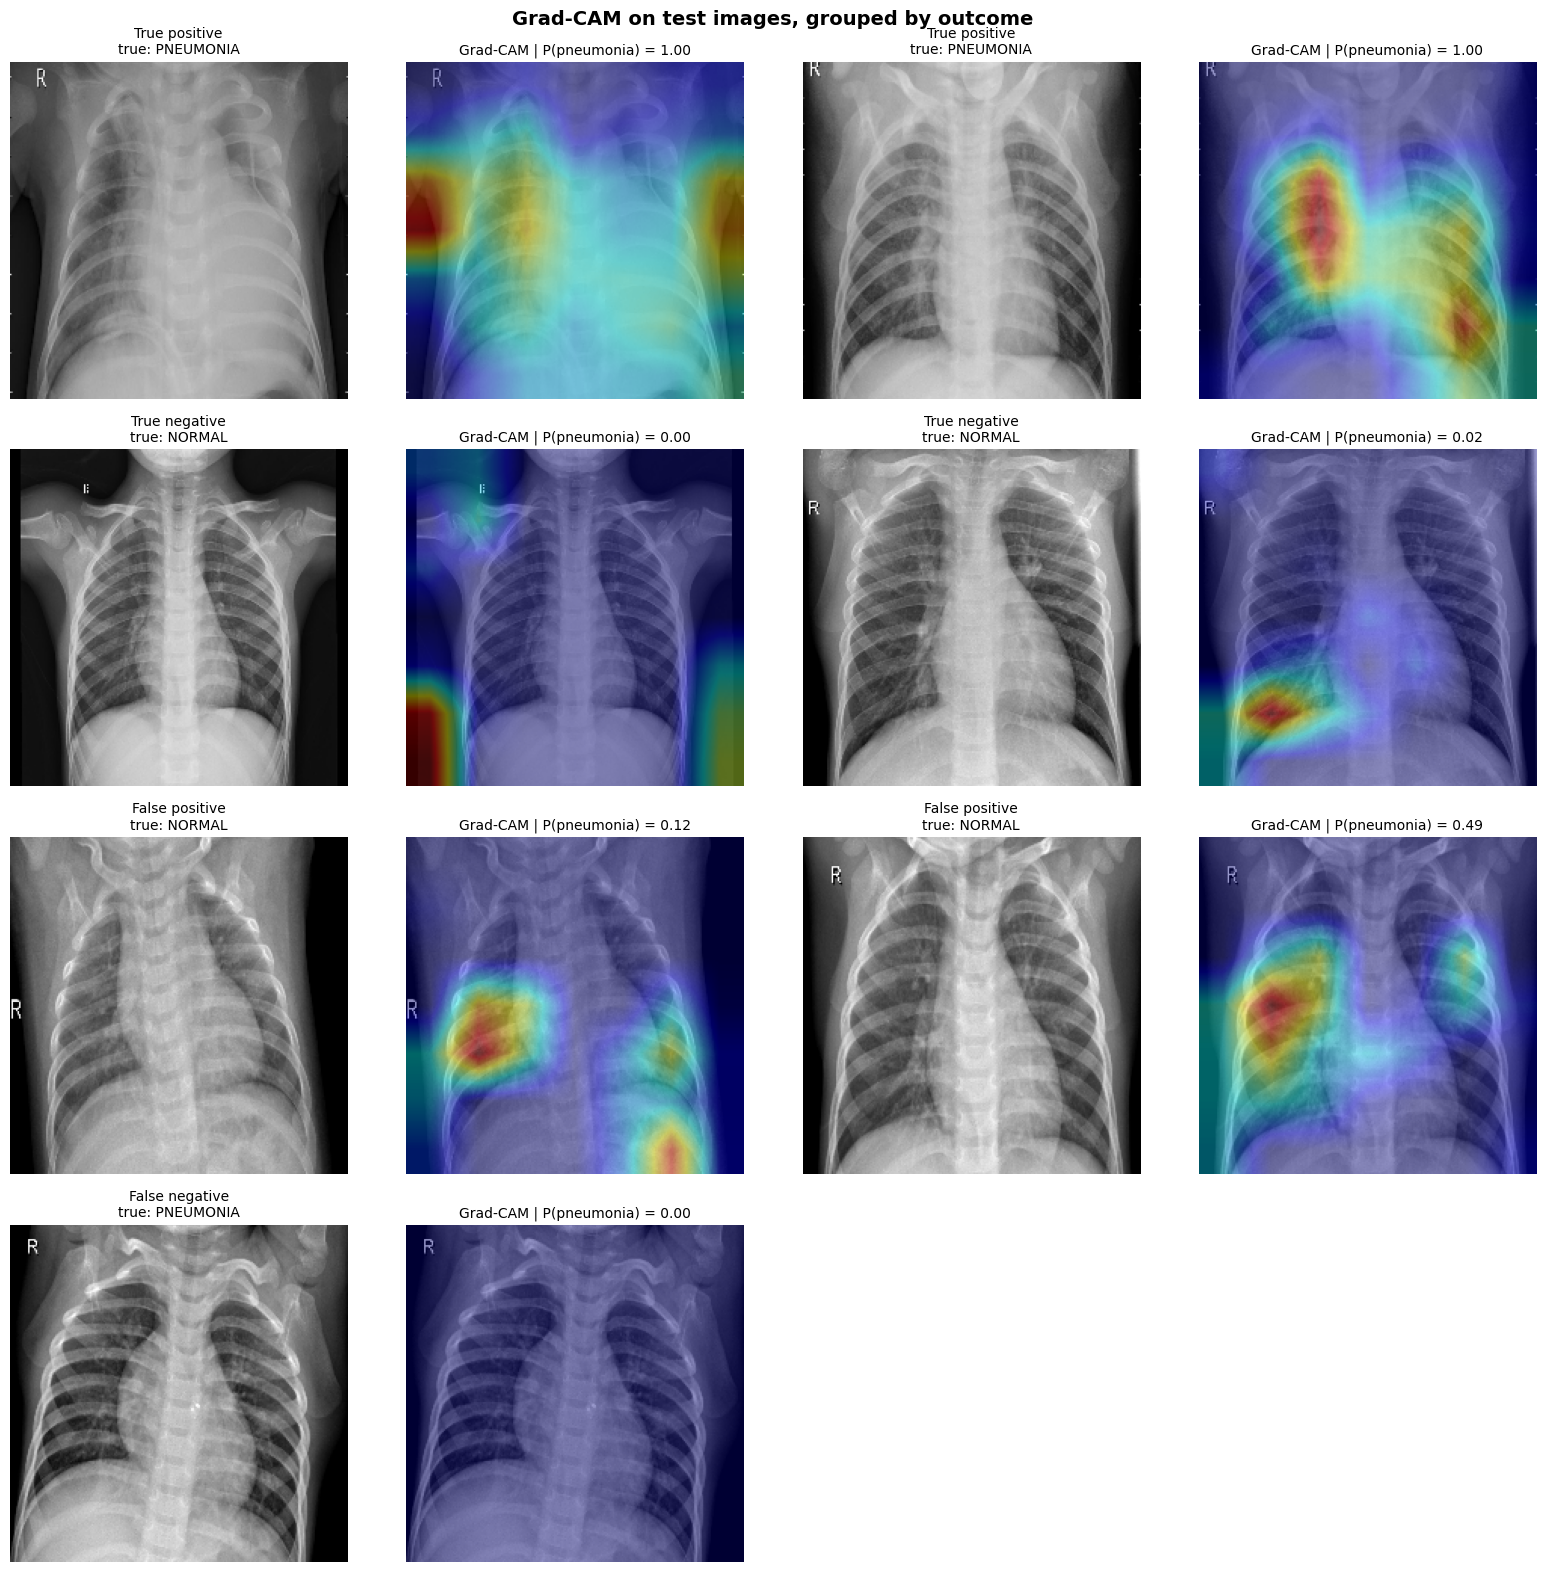

In [12]:
LAST_CONV = "conv5_block3_out"
grad_model = keras.Model(model.inputs, [model.get_layer(LAST_CONV).output, model.output])

def gradcam(batch):
    """Grad-CAM heatmap (values in [0, 1]) for the pneumonia probability."""
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(batch, training=False)
        score = pred[:, 0]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv_out, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy()

def explain(path):
    rgb = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, IMG_SIZE[::-1])
    batch = keras.applications.resnet50.preprocess_input(rgb.astype("float32"))[None]
    prob = float(model.predict(batch, verbose=0)[0, 0])
    cam = cv2.resize(gradcam(tf.constant(batch)), IMG_SIZE[::-1])
    heat = cv2.cvtColor(cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return rgb, cv2.addWeighted(rgb, 0.6, heat, 0.4, 0), prob

thr = thresholds["ResNet50 (fine-tuned)"]
pred_nn = (test_prob >= thr).astype(int)
groups = {"True positive": (y_test == 1) & (pred_nn == 1), "True negative": (y_test == 0) & (pred_nn == 0),
          "False positive": (y_test == 0) & (pred_nn == 1), "False negative": (y_test == 1) & (pred_nn == 0)}

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for row, (name, mask) in enumerate(groups.items()):
    idx = np.where(mask)[0]
    picks = rng.choice(idx, size=min(2, len(idx)), replace=False) if len(idx) else []
    for k in range(2):
        a_img, a_cam = axes[row, 2 * k], axes[row, 2 * k + 1]
        a_img.axis("off"); a_cam.axis("off")
        if k < len(picks):
            rgb, cam_img, prob = explain(test_paths[picks[k]])
            a_img.imshow(rgb); a_img.set_title(f"{name}\ntrue: {CLASSES[y_test[picks[k]]]}", fontsize=10)
            a_cam.imshow(cam_img); a_cam.set_title(f"Grad-CAM | P(pneumonia) = {prob:.2f}", fontsize=10)
plt.suptitle("Grad-CAM on test images, grouped by outcome", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Findings

Test set: 624 images from 428 patients (390 with pneumonia). Single run, seed 42. Values are estimate [95% CI].

| Model | AUC | Sensitivity @ 0.5 | Specificity @ 0.5 | F1 @ 0.5 |
|---|---|---|---|---|
| SVM (RBF) | 0.812 [0.776, 0.848] | 0.954 | 0.303 | 0.804 |
| Random Forest | 0.853 [0.825, 0.881] | 0.959 | 0.252 | 0.797 |
| **ResNet50 (fine-tuned)** | **0.971 [0.957, 0.983]** | **0.977 [0.960, 0.991]** | **0.808 [0.755, 0.860]** | **0.934 [0.913, 0.952]** |

- **Deep learning clearly beats the classical baselines.** The AUC confidence intervals do not overlap (0.97 vs. 0.81-0.85). The classical models detect most pneumonia cases but flag most healthy images as pneumonia (specificity 0.25-0.30).
- **The validation-tuned threshold did not transfer.** Maximizing Youden's J on the validation patients gave a threshold of 0.048 for the ResNet50, and on the test set this *lowered* specificity from 0.81 to 0.68 (sensitivity 0.997). The validation images are easier than the official test set, so a threshold tuned on them is too permissive. The threshold-free AUC and the default 0.5 operating point are the more trustworthy summaries here.
- **Validation scores overstate test performance for every model.** Validation AUC was about 0.97 for the classical models and 0.99+ for the ResNet50, against 0.81-0.85 and 0.97 on the test set. The classical models drop the most, which suggests their intensity and texture features pick up image-acquisition differences between the training and test portions of the dataset rather than disease alone.
- **Grad-CAM shows mostly plausible lung regions, but not always.** In the examples below (selected at the validation-tuned threshold), several heatmaps focus on the lungs, while at least two put strong activation on image borders and corners outside the lungs. That points to possible shortcut learning, so the ResNet50 results should not be read as proof of clinically meaningful features.

## 7. Limitations

- All images come from one source (pediatric patients at a single medical center), so performance on other hospitals, scanners or age groups is unknown.
- The official test set is known to look somewhat different from the training set, and the gap between validation and test performance reflects this distribution shift.
- The test set is small and its pneumonia/normal ratio differs from training. Confidence intervals are wide for specificity.
- The classical pipeline uses only simple handcrafted features; stronger classical baselines may close part of the gap.
- Research prototype, not a clinical tool.